# 用户购买预测建模

### 1.1 建模目标与时间窗口切分

A） **目标：** 能不能根据用户在大促开始**之前**的行为，提前判断谁会在大促这 2 天下单？

- 这不是「通用购买预测」，而是「大促期购买倾向预测」——用大促前 7 天的历史行为，预测大促 2 天内会不会下单。
- 而这正是真实的营销场景下，很实用的预测分析。在大促前圈出一批「可能买」的人，向ta们定向发券、定向触达。「用平时行为预测大促行为」是这个预测模型本身的定义。

B）**窗口切分**&#8203;

| | 时间段 | 天数 | 用途   |
| :--- | :--- | ---: |:-------|
| **观察窗** | 2017-11-25 00:00 – 12-01 23:59 | 7 天 | 特征 X |
| **预测窗** | 2017-12-02 00:00 – 12-03 23:59 | 2 天 | 标签 y |

**原则:** 用来预测的信息（观察窗）和要预测的事（预测窗），时间上**绝对不能重叠。


### 1.2 数据加载与样本总览

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = [
    'PingFang SC', 'Microsoft YaHei', 'SimHei',
    'Arial Unicode MS', 'WenQuanYi Micro Hei', 'Noto Sans CJK SC', 'sans-serif'
]
plt.rcParams['axes.unicode_minus'] = False

In [2]:
# 路径探测：兼容 VSCode / JupyterLab / 任意启动目录（与 03 notebook 同一套逻辑）
def find_project_root():
    if '__vsc_ipynb_file__' in globals():
        start = Path(globals()['__vsc_ipynb_file__']).parent
    else:
        start = Path.cwd()
    for p in [start] + list(start.parents):
        if (p / 'src').exists() and (p / 'data').exists():
            return p
    raise FileNotFoundError('找不到项目根目录（需同时含 src/ 和 data/）')

PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / 'data' / 'cleaned_data.csv'

df = pd.read_csv(DATA_PATH)
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')

In [3]:
# 窗口切分
OBS_START,  OBS_END  = '2017-11-25 00:00:00', '2017-12-01 23:59:59'
PRED_START, PRED_END = '2017-12-02 00:00:00', '2017-12-03 23:59:59'

obs  = df[(df['datetime'] >= OBS_START)  & (df['datetime'] <= OBS_END)]
pred = df[(df['datetime'] >= PRED_START) & (df['datetime'] <= PRED_END)]

# 样本与标签分布
all_users   = set(df['user_id'])
pred_buyers = set(pred.loc[pred['behavior_type'] == 'buy', 'user_id'])

n_total = len(all_users)
n_pos   = len(pred_buyers)
n_neg   = n_total - n_pos

In [4]:
print(f"数据文件                : {DATA_PATH.name}")
print(f"总记录数                : {len(df):,}")
print(f"时间范围                : {df['datetime'].min()} ~ {df['datetime'].max()}")
print("-" * 52)
print(f"观察窗 11/25–12/01 行为 : {len(obs):,} 条")
print(f"预测窗 12/02–12/03 行为 : {len(pred):,} 条")
print("-" * 52)
print(f"样本量（全平台活跃用户）: {n_total:,}")
print(f"正样本（预测窗内买过）  : {n_pos:,}  （{n_pos/n_total:.1%}）")
print(f"负样本（预测窗内没买）  : {n_neg:,}  （{n_neg/n_total:.1%}）")

数据文件                : cleaned_data.csv
总记录数                : 999,530
时间范围                : 2017-11-25 00:00:00 ~ 2017-12-03 23:59:50
----------------------------------------------------
观察窗 11/25–12/01 行为 : 725,108 条
预测窗 12/02–12/03 行为 : 274,422 条
----------------------------------------------------
样本量（全平台活跃用户）: 9,739
正样本（预测窗内买过）  : 3,036  （31.2%）
负样本（预测窗内没买）  : 6,703  （68.8%）


### 1.3 标签 (y) 构造

**二分类标签定义：** 每个用户在预测窗（12/02–12/03）内**是否至少购买过一次**：

- 买过 → y = 1
- 没买 → y = 0

**口径边界：** 这里的 y = 0 只代表**在这 2 天窗口内没买**，不等于用户永久流失（右删失）。


In [5]:
# 复用 1.2 已算好的 pred_buyers（预测窗内购买的用户集合）
labels = pd.DataFrame({'user_id': sorted(all_users)})
labels['y'] = labels['user_id'].isin(pred_buyers).astype(int)

dist = labels['y'].value_counts().sort_index()
print(f"标签表：{len(labels):,} 行")
print(f"  y = 0（预测窗内未购买）：{dist[0]:,} 人（{dist[0] / len(labels):.1%}）")
print(f"  y = 1（预测窗内已购买）：{dist[1]:,} 人（{dist[1] / len(labels):.1%}）")

标签表：9,739 行
  y = 0（预测窗内未购买）：6,703 人（68.8%）
  y = 1（预测窗内已购买）：3,036 人（31.2%）


### 1.4 特征工程（X）

**所有特征只能用观察窗（11/25–12/01）的数据算。**

9 个特征分五组：

| 组 | 特征 | 含义 |
| :--- | :--- | :--- |
| 行为强度 | `pv_cnt` / `fav_cnt` / `cart_cnt` | 观察窗内浏览 / 收藏 / 加购次数 |
| 购买 | `obs_buy_cnt` | 观察窗内购买次数（预期最强） |
| 活跃 | `active_days` | 有任意行为的去重天数 |
|  | `days_since_last_active` | 最后活跃距 12/01 的天数（平台黏性） |
| 广度 | `n_cats` | 浏览过的**去重品类数** |
| 效率 | `cart_depth` | 加购转化率 = `cart_cnt / pv_cnt` |
| 购买近期性 | `obs_recency_days` | 观察窗内最后购买距 12/01 天数（RFM 的 R） |

In [6]:
# 全部只用观察窗数据
OBS_END_DATE = pd.Timestamp('2017-12-01')

# 1) 行为频次：pv / fav / cart / buy 次数
cnt = (obs.groupby(['user_id', 'behavior_type']).size()
          .unstack(fill_value=0)
          .reindex(columns=['pv', 'fav', 'cart', 'buy'], fill_value=0)
          .rename(columns={'pv': 'pv_cnt', 'fav': 'fav_cnt',
                           'cart': 'cart_cnt', 'buy': 'obs_buy_cnt'}))
# 2) 活跃天数（有任意行为的去重天数）
active_days = (obs.assign(date=obs['datetime'].dt.normalize())
                  .groupby('user_id')['date'].nunique()
                  .rename('active_days'))

# 3) 最后活跃距 12/01 的天数
last_active = obs.groupby('user_id')['datetime'].max().dt.normalize()
days_since_last_active = (OBS_END_DATE - last_active).dt.days.rename('days_since_last_active')

# 4) 浏览广度：浏览过的去重品类数
n_cats = (obs.loc[obs['behavior_type'] == 'pv']
             .groupby('user_id')['category_id'].nunique()
             .rename('n_cats'))

# 5) 加购转化率
cart_depth = (cnt['cart_cnt'] / cnt['pv_cnt'].replace(0, np.nan)).fillna(0).rename('cart_depth')

# 6) 观察窗内最后购买距 12/01 的天数（RFM 的 R）
last_buy = (obs.loc[obs['behavior_type'] == 'buy']
               .groupby('user_id')['datetime'].max().dt.normalize())
obs_recency_days = (OBS_END_DATE - last_buy).dt.days.rename('obs_recency_days')


In [7]:
#  汇总成特征表（以全量活跃用户为索引，保证每人一行）
X = (cnt.join([active_days, days_since_last_active, n_cats, cart_depth, obs_recency_days],
              how='outer')
        .reindex(sorted(all_users)))

X['obs_recency_days'] = X['obs_recency_days'].fillna(8)   # 哨兵值：窗口内从没买过
X = X.fillna(0)

print(f"特征表：{X.shape[0]:,} 行 × {X.shape[1]} 列")
print(f"特征：{list(X.columns)}")
print(f"缺失值：{int(X.isna().sum().sum())}")
X.head()

特征表：9,739 行 × 9 列
特征：['pv_cnt', 'fav_cnt', 'cart_cnt', 'obs_buy_cnt', 'active_days', 'days_since_last_active', 'n_cats', 'cart_depth', 'obs_recency_days']
缺失值：0


,pv_cnt,fav_cnt,cart_cnt,obs_buy_cnt,active_days,days_since_last_active,n_cats,cart_depth,obs_recency_days
user_id,,,,,,,,,
1,41.0,0.0,0.0,0.0,7.0,0.0,16.0,0.000000,8.0
100,79.0,6.0,0.0,8.0,6.0,0.0,25.0,0.000000,3.0
115,204.0,10.0,3.0,0.0,7.0,0.0,35.0,0.014706,8.0
117,124.0,0.0,1.0,10.0,6.0,1.0,14.0,0.008065,3.0
118,63.0,0.0,0.0,0.0,7.0,0.0,16.0,0.000000,8.0


In [8]:
# 1.4 特征体检：相关性矩阵（防共线，建模前必做）
corr = X.corr(method='spearman')
print("Spearman 相关系数矩阵：")
print(corr.round(3).to_string())

print("\n相关系数 |ρ| > 0.8 的特征对：")
pairs = [(corr.columns[i], corr.columns[j], round(corr.iloc[i, j], 3))
         for i in range(len(corr.columns)) for j in range(i + 1, len(corr.columns))
         if abs(corr.iloc[i, j]) > 0.8]
for a, b, v in sorted(pairs, key=lambda x: -abs(x[2])):
    print(f"  {a:24s} ~ {b:24s} ρ = {v}")
if not pairs:
    print("  （无）")


Spearman 相关系数矩阵：
                        pv_cnt  fav_cnt  cart_cnt  obs_buy_cnt  active_days  days_since_last_active  n_cats  cart_depth  obs_recency_days
pv_cnt                   1.000    0.293     0.474        0.331        0.682                  -0.369   0.864       0.070            -0.261
fav_cnt                  0.293    1.000    -0.054        0.122        0.241                  -0.134   0.283      -0.164            -0.097
cart_cnt                 0.474   -0.054     1.000        0.273        0.383                  -0.207   0.442       0.837            -0.221
obs_buy_cnt              0.331    0.122     0.273        1.000        0.363                  -0.195   0.334       0.130            -0.862
active_days              0.682    0.241     0.383        0.363        1.000                  -0.494   0.700       0.114            -0.284
days_since_last_active  -0.369   -0.134    -0.207       -0.195       -0.494                   1.000  -0.370      -0.074             0.237
n_cats           

**特征口径细节：**

- **`obs_recency_days` 对「窗口内没买过」的人填哨兵值 8**，不是 0。填 0 会被模型误读成"刚刚买过"，方向完全反了。
- **不放 `n_items`（去重商品数）**&#8203;：它与 `pv_cnt` 的 Spearman ρ = **0.989**，几乎完全冗余（本平台浏览不重复看同一商品）。改用 `n_cats`（与 `pv_cnt` 的 Spearman ρ = 0.864），提供品类级视角。
- **已知共线（保留但需知晓）**&#8203;：`obs_buy_cnt` ~ `obs_recency_days` ρ = −0.862（RFM 的 F 与 R 天然相关）；`cart_cnt` ~ `cart_depth` ρ = 0.837（函数依赖）。

### 1.5 建模表合并、泄漏自检与特征预测力诊断

**任务：** 把特征 X 和标签 y 拼成一张建模表，然后**证明没有标签泄漏**。

- **时间窗口不重叠** —— 用 `assert` 硬性验证「观察窗最后时刻 < 预测窗第一时刻」
- **特征与标签的相关性排查** —— 如果某个特征跟 y 的相关性高得离谱（|ρ| > 0.9），高度可疑：正常的预测特征不该有这么强的相关性（真有的话，多半是这个特征偷偷用了未来信息）

> 在建模里这一步很关键：**因为泄漏是建模非常致命的错误，而且它不会报错，只会返回一个虚高的good performance。**&#8203;

In [9]:
# 1.5 建模表合并
model_df = X.join(labels.set_index('user_id')).rename_axis('user_id').reset_index()

print(f"建模表：{model_df.shape[0]:,} 行 × {model_df.shape[1]} 列")
print(f"列名：{list(model_df.columns)}")

建模表：9,739 行 × 11 列
列名：['user_id', 'pv_cnt', 'fav_cnt', 'cart_cnt', 'obs_buy_cnt', 'active_days', 'days_since_last_active', 'n_cats', 'cart_depth', 'obs_recency_days', 'y']


In [10]:
# 泄漏自检 1：时间窗口不重叠
obs_max, pred_min = obs['datetime'].max(), pred['datetime'].min()
print(f"\n观察窗最后时刻：{obs_max}")
print(f"预测窗第一时刻：{pred_min}")
assert obs_max < pred_min, "❌ 时间窗口重叠，存在泄漏！"
print("✅ 时间窗口无重叠")


观察窗最后时刻：2017-12-01 23:59:59
预测窗第一时刻：2017-12-02 00:00:00
✅ 时间窗口无重叠


In [11]:
# 泄漏自检 2：特征与标签的相关性排查
feat_cols = list(X.columns)
corr_y = (model_df[feat_cols + ['y']].corr(method='spearman')['y']
             .drop('y').sort_values(key=abs, ascending=False))
print("\n各特征与标签 y 的 Spearman 相关性（降序）：")
print(corr_y.round(3).to_string())

susp = corr_y[corr_y.abs() > 0.9]
print(f"\n|ρ| > 0.9 的疑似泄漏特征：{list(susp.index) if len(susp) else '无 ✅'}")

#  最终体检
print(f"\n建模表体检：行数 {len(model_df):,} | 缺失 {int(model_df.isna().sum().sum())}"
      f" | 正样本率 {model_df['y'].mean():.1%}")


各特征与标签 y 的 Spearman 相关性（降序）：
obs_buy_cnt               0.151
obs_recency_days         -0.135
cart_depth                0.053
cart_cnt                  0.047
days_since_last_active   -0.023
active_days               0.013
fav_cnt                  -0.007
pv_cnt                   -0.004
n_cats                    0.003

|ρ| > 0.9 的疑似泄漏特征：无 ✅

建模表体检：行数 9,739 | 缺失 0 | 正样本率 31.2%


我们可以看到各特征与标签 Y 的 Spearman 相关性整体偏弱，最高的 `obs_buy_cnt` 也只有 0.151。**但这个工具有个盲区**，它只能发现「平滑渐变」的关系，发现不了「台阶式跳跃」。所以我们还要用下面的工具（分组购买率）再量一遍，因为它专门看分组之间的差异，不受这个盲区影响

In [12]:
# 特征预测力初探：看分组购买率，而不是只看相关系数
print("=" * 58)
print("关键特征的分组购买率（比相关系数更能说明问题）")
print("=" * 58)

# 老客 vs 新客
g = (model_df.assign(组=np.where(model_df['obs_buy_cnt'] > 0, '观察窗买过', '观察窗没买'))
         .groupby('组')['y'].agg(['mean', 'size']))
g['mean'] = (g['mean'] * 100).round(1)
print("\n【obs_buy_cnt】老客 vs 新客：")
print(g.to_string())

# obs_buy_cnt 分档（看单调性）
model_df['_bin'] = (model_df['obs_buy_cnt'].clip(upper=4)
                       .map({0: '0次', 1: '1次', 2: '2次', 3: '3次', 4: '≥4次'}))
print("\n【obs_buy_cnt】分档（看是否单调）：")
print((model_df.groupby('_bin')['y'].agg(['mean', 'size'])
             .assign(mean=lambda d: (d['mean'] * 100).round(1))).to_string())

# 浏览量五分位（对照：预期完全平）
model_df['_pvq'] = pd.qcut(model_df['pv_cnt'], 5, duplicates='drop')
print("\n【pv_cnt】五分位（对照：预期无预测力）：")
print((model_df.groupby('_pvq', observed=True)['y'].agg(['mean', 'size'])
             .assign(mean=lambda d: (d['mean'] * 100).round(1))).to_string())

model_df.drop(columns=['_bin', '_pvq'], inplace=True)

关键特征的分组购买率（比相关系数更能说明问题）

【obs_buy_cnt】老客 vs 新客：
       mean  size
组                
观察窗买过  36.1  5716
观察窗没买  24.2  4023

【obs_buy_cnt】分档（看是否单调）：
      mean  size
_bin            
0次    24.2  4023
1次    31.7  2349
2次    35.5  1333
3次    35.4   813
≥4次   45.7  1221

【pv_cnt】五分位（对照：预期无预测力）：
                mean  size
_pvq                      
(-0.001, 17.0]  32.8  2029
(17.0, 34.0]    29.5  1903
(34.0, 60.0]    30.8  1957
(60.0, 105.0]   30.7  1915
(105.0, 609.0]  32.0  1935


**解读：**
- 5,716 个「观察窗内买过东西」的人里，有 **2,063 人（36.1%）在大促期间又买了**；4,023 个「观察窗内没买」的人里，只有 **973 人（24.2%）在大促买了**，这说明「有没有购买历史」确实能区分人群。
- 把「观察窗内买过几次」分成 5 档，我们发现每档的大促购买率呈基本单调上升规律，从 0 次的 24.2% 涨到 ≥4 次的 45.7%，**接近翻倍**。说明这个特征不只是「买过/没买过」这个二分有用，而是**买得越多、越可能再买**。
- 把所有人按「浏览了多少次」从少到多排成 5 等份（最高组比最低组的浏览量大 6 倍以上），看每份的大促购买率。五组都在 29.5%–32.8% 之间，**几乎没有任何差异**——「浏览 5 次还是 500 次」对大促买不买完全没有影响。这是特征无效的典型表现。

**两个结论为什么不一样？** 因为 Spearman 看不透「台阶式」关系。因此**两个工具必须合起来看**：Spearman 负责筛出「平滑型」的强特征，分组购买率负责补上「台阶型」的关系。

**这也是后面要同时训练多种模型的原因**：——树模型理论上更擅长自动捕捉这种非线性关系，而逻辑回归则假设线性。**至于哪种在本数据上更优，要用交叉验证来定。**


### 1.6 训练集 / 测试集切分

**切分方式：80 / 20，分层抽样。** - 全量正样本率 31.2%。纯随机切可能让两边的正样本率略有偏差；加上 `stratify=y` 保证两边都是 31.2%，模型对比才公平。

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score

# 特征列 / 标签列
FEATURES = ['pv_cnt', 'fav_cnt', 'cart_cnt', 'obs_buy_cnt', 'active_days',
            'days_since_last_active', 'n_cats', 'cart_depth', 'obs_recency_days']
TARGET = 'y'

X_all = model_df[FEATURES]
y_all = model_df[TARGET]

# 80 / 20 分层切分
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=0.20,
    stratify=y_all,      # 保持训练/测试两边正负样本比例一致
    random_state=42      # 固定随机种子，保证结果可复现
)

print(f"全量   ：{len(X_all):,} 人 | 正样本率 {y_all.mean():.1%}")
print("-" * 52)
print(f"训练集 ：{len(X_train):,} 人 | 正样本率 {y_train.mean():.1%} | 正样本 {int(y_train.sum()):,}")
print(f"测试集 ：{len(X_test):,} 人 | 正样本率 {y_test.mean():.1%} | 正样本 {int(y_test.sum()):,}")

# 切分自检：两边不能有重叠
assert len(set(X_train.index) & set(X_test.index)) == 0, "训练集与测试集存在重叠！"
print("\n✅ 训练集与测试集无重叠")

全量   ：9,739 人 | 正样本率 31.2%
----------------------------------------------------
训练集 ：7,791 人 | 正样本率 31.2% | 正样本 2,429
测试集 ：1,948 人 | 正样本率 31.2% | 正样本 607

✅ 训练集与测试集无重叠


### 1.7 基线模型（Baseline）

In [14]:
# 前置：确定「最强单特征」—— 这是选择基线的依据
print("=" * 72)
print("各特征单独使用时的 AUC（决定基线该选谁）")
print("=" * 72)

single_auc = {}
for f in FEATURES:
    s = X_test[f].values.astype(float)
    # 特征方向不定（有的越大越可能买、有的越小越可能买），两个方向都试、取较优
    single_auc[f] = max(roc_auc_score(y_test, s), roc_auc_score(y_test, -s))

single_series = pd.Series(single_auc).sort_values(ascending=False)
print(single_series.round(4).to_string())
print("-" * 72)
print(f"⭐ 最强单特征 = {single_series.index[0]}（AUC = {single_series.iloc[0]:.4f}）")
print(f"   最弱单特征 = {single_series.index[-1]}（AUC = {single_series.iloc[-1]:.4f}）")
print(f"\n→ 基线选「最强单特征」：只有超过它，多特征建模才算有增益")


各特征单独使用时的 AUC（决定基线该选谁）
obs_buy_cnt               0.5790
obs_recency_days          0.5627
cart_depth                0.5259
cart_cnt                  0.5207
n_cats                    0.5131
fav_cnt                   0.5059
days_since_last_active    0.5045
pv_cnt                    0.5026
active_days               0.5023
------------------------------------------------------------------------
⭐ 最强单特征 = obs_buy_cnt（AUC = 0.5790）
   最弱单特征 = active_days（AUC = 0.5023）

→ 基线选「最强单特征」：只有超过它，多特征建模才算有增益


In [15]:
# Baseline 1：随机打分
np.random.seed(42)
score_random = np.random.rand(len(y_test))

# Baseline 2：全猜「不买」
pred_all_zero = np.zeros(len(y_test))

# Baseline 3：单特征规则（观察窗买过 → 猜会买）
score_rule = (X_test['obs_buy_cnt'] > 0).astype(int)

# Baseline 3b：直接用 obs_buy_cnt 原始值当分数
score_rule_raw = X_test['obs_buy_cnt'].values

In [16]:
# 四个 baseline 的 accuracy 对比
# 注意：accuracy 需要「买 / 不买」的硬判断，连续分数必须先定一个阈值
print("=" * 64)
print("四个 baseline 在测试集上评估 的 AUC 与 accuracy 对比")
print("=" * 64)
print(f"{'Baseline':<34}{'AUC':>9}{'accuracy':>11}")
print("-" * 64)

for name, score, thr in [
    ('1)  随机打分',                       score_random,                0.5),
    ('2)  对所有人都预测「不买」',             pred_all_zero,            0.5),
    ('3)  单特征规则（观察窗内买过→猜会买',     score_rule,              0.5),
    ('3b) 直接用obs_buy_cnt 原值当分数',    score_rule_raw,             0.0),
]:
    auc = roc_auc_score(y_test, score)
    acc = accuracy_score(y_test, (score > thr).astype(int))
    print(f"{name:<34}{auc:>9.4f}{acc:>11.1%}")

print("-" * 64)
print("注：accuracy 必须先定「多少分算买」的阈值（随机数用 0.5、计数用 >0）；")
print("    阈值一换 accuracy 就变 —— 这正是它不如 AUC 好用的地方。")


四个 baseline 在测试集上评估 的 AUC 与 accuracy 对比
Baseline                                AUC   accuracy
----------------------------------------------------------------
1)  随机打分                             0.5104      50.2%
2)  对所有人都预测「不买」                      0.5000      68.8%
3)  单特征规则（观察窗内买过→猜会买                 0.5530      51.2%
3b) 直接用obs_buy_cnt 原值当分数             0.5790      51.2%
----------------------------------------------------------------
注：accuracy 必须先定「多少分算买」的阈值（随机数用 0.5、计数用 >0）；
    阈值一换 accuracy 就变 —— 这正是它不如 AUC 好用的地方。


**基线结果解读：**

**及格线定在 0.579，accuracy 在该项目中不作为评估指标。**

- 最强单特征 = `obs_buy_cnt`（AUC = 0.5790), 我们选择「最强单特征」作为基线，模型只有超过它，多特征建模才算有增益。
- accuracy 最高的是「全猜不买」（68.8%），但它一个买家都没找出来，AUC 只有 0.500。
- AUC 最高的是「原值规则」（0.579），但它的 accuracy 只有 51.2%。
- 两个指标给出相反的结论，说明 accuracy 在这里不可靠，原因有两点：一是「没买」占了 68.8%，任何偏向多数类的策略都能拿到高 accuracy；二是 accuracy 必须先人为设定"多少分算买"的阈值，阈值一挪分数就变，而 AUC 不需要阈值。

### 1.8 模型训练与交叉验证

**任务：** 训练三个候选模型，在**训练集**上用 5 折交叉验证比较它们的表现。

| 模型 | 特点 |
| :--- | :--- |
| 逻辑回归（LR） | 最简单、可解释性最强（系数可直接看方向） |
| 随机森林（RF） | 树模型代表，自动捕捉非线性和交互 |
| XGBoost | 梯度提升，工业界常用 |

**为什么用交叉验证，而不是再切一个验证集：**

- 训练集只有 7,791 条样本，再切 15% 出来单做验证太浪费。5 折 CV 让**每一份数据都当过一次验证集**，数据利用率更高、结果更稳。

**为什么逻辑回归要套 Pipeline：**

- LR 需要特征标准化，而标准化的参数（均值、标准差）**只能在每个 fold 的训练部分上算**。Pipeline 会自动处理这件事，避免把验证集的信息泄漏进模型。

> ⚠️ 测试集在这一步**完全不参与**，下一章节我们会进行模型性能与测试集评估。

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from xgboost import XGBClassifier

# 5 折分层交叉验证（固定随机种子，结果可复现）
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 三个候选模型
models = {
    '逻辑回归 (LR)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    '随机森林 (RF)': RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric='logloss', random_state=42, n_jobs=-1),
}

print("=" * 92)
print("1.8 三个模型的 5 折交叉验证（在训练集内进行）")
print("=" * 92)
print(f"{'模型':<20}{'训练集 AUC 均值':>17}{'验证集 AUC 均值':>17}{'标准差':>10}{'差距':>10}")
print("-" * 92)

cv_results = {}
for name, model in models.items():
    # return_train_score=True → 同时拿到每折在「训练部分」和「验证部分」的分数
    r = cross_validate(model, X_train, y_train, cv=cv, scoring='roc_auc',
                       return_train_score=True, n_jobs=-1)
    tr, va = r['train_score'], r['test_score']
    cv_results[name] = {'train': tr, 'valid': va}
    print(f"{name:<20}{tr.mean():>17.4f}{va.mean():>17.4f}{va.std():>10.4f}"
          f"{tr.mean() - va.mean():>10.4f}")

print("-" * 92)
best_name = max(cv_results, key=lambda k: cv_results[k]['valid'].mean())
print(f"⭐ 最优模型（按验证集 AUC）= {best_name}"
      f"（AUC = {cv_results[best_name]['valid'].mean():.4f}）")
print(f"参考：及格线（最强单特征 obs_buy_cnt）= 0.5790")

print("\n各模型 5 折明细：")
for name, d in cv_results.items():
    print(f"  {name}")
    print(f"    训练集 {np.round(d['train'], 4)}")
    print(f"    验证集 {np.round(d['valid'], 4)}")


1.8 三个模型的 5 折交叉验证（在训练集内进行）
模型                         训练集 AUC 均值       验证集 AUC 均值       标准差        差距
--------------------------------------------------------------------------------------------
逻辑回归 (LR)                      0.6041           0.6015    0.0142    0.0026
随机森林 (RF)                      0.9476           0.5755    0.0103    0.3720
XGBoost                        0.7042           0.5806    0.0160    0.1236
--------------------------------------------------------------------------------------------
⭐ 最优模型（按验证集 AUC）= 逻辑回归 (LR)（AUC = 0.6015）
参考：及格线（最强单特征 obs_buy_cnt）= 0.5790

各模型 5 折明细：
  逻辑回归 (LR)
    训练集 [0.6074 0.6064 0.6051 0.5968 0.6048]
    验证集 [0.5937 0.5925 0.5966 0.6298 0.5948]
  随机森林 (RF)
    训练集 [0.9473 0.949  0.9445 0.9493 0.9477]
    验证集 [0.5581 0.5694 0.5818 0.5854 0.5831]
  XGBoost
    训练集 [0.7059 0.7053 0.6996 0.701  0.7094]
    验证集 [0.5676 0.5601 0.5836 0.6064 0.5855]


**结论：逻辑回归（LR）最优，也是三个模型里唯一没有过拟合的。**

- **LR 差距 0.003**：训练集和验证集几乎一样，说明它学到的是真规律
- **RF 差距 0.372**：训练集 0.9476，验证集只有 0.5755 —— 严重过拟合
- **XGBoost 差距 0.124**：同样过拟合，但比 RF 轻
- **对照及格线 AUC = 0.579：** 只有 LR 明显过线（+0.022），XGBoost 勉强（+0.002），RF 没过线（−0.004）。

**树模型为什么过拟合：**
- 1.5 的分组购买率诊断已经给出答案——本数据真正有效的信号很集中——只有 `obs_buy_cnt` 一个特征表现出明显的分组差异（大促购买率 24.2% → 45.7%），其余 8 个特征几乎没有区分力。信号少、样本又不大（训练集 7,791 条），树模型会把噪声也当成规律学进去；LR 结构简单、自带正则化，反而更稳。

**因此根据数据的关系形态和过拟合程度，选逻辑回归（LR）进行测试集评估。**

### 1.9 测试集评估

把 1.8 选出的逻辑回归拿到 **测试集**上跑一次，查看我们模型的性能。

**评估四样指标：**

| 指标 | 作用 |
| :--- | :--- |
| **AUC** | 主指标——排序能力，跟及格线 0.579 比 |
| **Lift@TopK** | 业务指标——圈出前 K% 的人，命中率是全域几倍 |
| **混淆矩阵 / Recall** | 看"真买家捞回来多少" |
| **Accuracy** | 对照展示——用来说明它为什么不能当主指标 |

In [18]:
# 用 1.8 选出的 LR 模型，在测试集上评估
best_model = models['逻辑回归 (LR)']
best_model.fit(X_train, y_train)                 # 只在训练集上 fit

y_prob = best_model.predict_proba(X_test)[:, 1]  # 每个用户的「购买倾向分」

print("=" * 68)
print("测试集评估（LR 模型）")
print("=" * 68)

# 主指标：AUC
test_auc = roc_auc_score(y_test, y_prob)
print(f"AUC（主指标）    = {test_auc:.4f}")
print(f"  对比 · 及格线   = 0.5790（最强单特征）"
      f"  →  {'✅ 过线' if test_auc > 0.579 else '❌ 未过线'}")
print(f"  对比 · CV 验证  = 0.6015")

# 业务指标：Lift@Top10%
def lift_at_k(y_true, y_prob, k=0.10):
    n = max(1, int(len(y_true) * k))
    order = np.argsort(-y_prob)          # 按预测概率从高到低排
    top = np.asarray(y_true)[order[:n]]
    return top.mean(), np.mean(y_true), n

top_rate, base_rate, n_top = lift_at_k(y_test, y_prob, 0.10)
print(f"\nLift@Top10%（业务指标）")
print(f"  模型挑出的前 {n_top} 人，实际购买率 = {top_rate:.1%}")
print(f"  全域平均购买率                     = {base_rate:.1%}")
print(f"  → Lift = {top_rate / base_rate:.2f} 倍")



测试集评估（LR 模型）
AUC（主指标）    = 0.5862
  对比 · 及格线   = 0.5790（最强单特征）  →  ✅ 过线
  对比 · CV 验证  = 0.6015

Lift@Top10%（业务指标）
  模型挑出的前 194 人，实际购买率 = 44.8%
  全域平均购买率                     = 31.2%
  → Lift = 1.44 倍


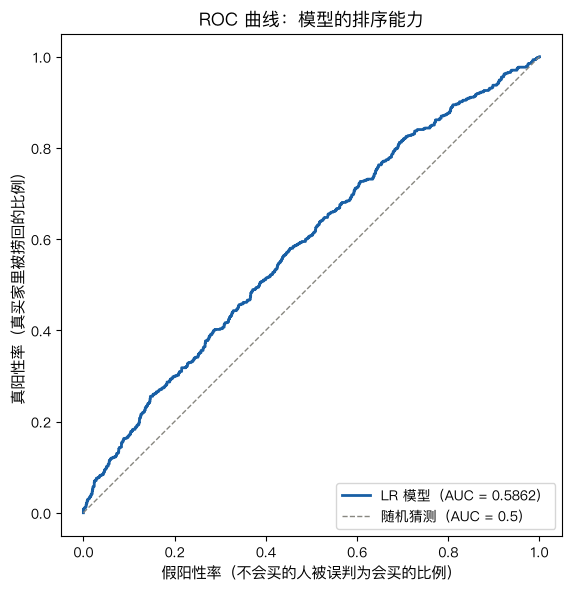

In [19]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color='#185FA5', linewidth=2,
        label=f'LR 模型（AUC = {test_auc:.4f}）')
ax.plot([0, 1], [0, 1], color='#888780', linewidth=1,
        linestyle='--', label='随机猜测（AUC = 0.5）')

ax.set_xlabel('假阳性率（不会买的人被误判为会买的比例）', fontsize=11)
ax.set_ylabel('真阳性率（真买家里被捞回的比例）', fontsize=11)
ax.set_title('ROC 曲线：模型的排序能力', fontsize=13)
ax.legend(loc='lower right', fontsize=10)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import (confusion_matrix, precision_score,
                             recall_score, f1_score, accuracy_score)

# 混淆矩阵：按业务策略取 Top10%
k = 0.10
n_top = max(1, int(len(y_test) * k))
order = np.argsort(-y_prob)                # 按预测概率从高到低排
y_pred_top = np.zeros(len(y_test), dtype=int)
y_pred_top[order[:n_top]] = 1              # 分数最高的前 10% 判为「会买」

cm = confusion_matrix(y_test, y_pred_top)
tn, fp, fn, tp = cm.ravel()

print("=" * 72)
print(f"混淆矩阵（策略：取预测分数最高的前 {k:.0%}，共 {n_top} 人）")
print("=" * 72)
print(f"  真不买 · 判不买 = {tn:>5}（正确放过）  |  真不买 · 判买 = {fp:>4}（白花钱）")
print(f"  真买了 · 判不买 = {fn:>5}（漏掉）      |  真买了 · 判买 = {tp:>4}（捞到）")
print(f"\n  Precision（发出的券有效比例） = {precision_score(y_test, y_pred_top):.3f}")
print(f"  Recall（捞回真买家的比例）    = {recall_score(y_test, y_pred_top):.3f}")
print(f"  F1                           = {f1_score(y_test, y_pred_top):.3f}")

# 附注：为什么不用默认阈值 0.5
y_pred_05 = (y_prob >= 0.5).astype(int)
print(f"\n【附注】若按默认阈值 0.5：判为「会买」仅 {int(y_pred_05.sum())} 人，"
      f"捞回真买家 {recall_score(y_test, y_pred_05):.1%}")
print("  原因：全域购买率只有 31.2%，模型概率普遍低于 0.5，用 0.5 一刀切几乎全判「不买」。")
print("  → 所以本场景不用固定阈值，而是按预算取 TopK。")

# 按预算取 TopK（找合适的圈人比例）
print("\n" + "=" * 72)
print("按预算取 TopK（不用固定阈值）")
print("=" * 72)
print(f"{'取前 K':<10}{'人数':>8}{'这批人购买率':>14}{'Lift':>9}{'捞到真买家':>12}")
print("-" * 72)
for kk in [0.05, 0.10, 0.20, 0.30, 0.50, 1.00]:
    n = max(1, int(len(y_test) * kk))
    o = np.argsort(-y_prob)
    top = np.asarray(y_test)[o[:n]]
    print(f"{kk:>6.0%}    {n:>8,}{top.mean():>13.1%}"
          f"{top.mean() / y_test.mean():>9.2f}{top.sum() / y_test.sum():>11.1%}")
print("-" * 72)
print(f"全域基准购买率 = {y_test.mean():.1%} | 真买家总数 = {int(y_test.sum()):,}")


混淆矩阵（策略：取预测分数最高的前 10%，共 194 人）
  真不买 · 判不买 =  1234（正确放过）  |  真不买 · 判买 =  107（白花钱）
  真买了 · 判不买 =   520（漏掉）      |  真买了 · 判买 =   87（捞到）

  Precision（发出的券有效比例） = 0.448
  Recall（捞回真买家的比例）    = 0.143
  F1                           = 0.217

【附注】若按默认阈值 0.5：判为「会买」仅 36 人，捞回真买家 3.1%
  原因：全域购买率只有 31.2%，模型概率普遍低于 0.5，用 0.5 一刀切几乎全判「不买」。
  → 所以本场景不用固定阈值，而是按预算取 TopK。

按预算取 TopK（不用固定阈值）
取前 K            人数        这批人购买率     Lift       捞到真买家
------------------------------------------------------------------------
    5%          97        50.5%     1.62       8.1%
   10%         194        44.8%     1.44      14.3%
   20%         389        42.2%     1.35      27.0%
   30%         584        38.7%     1.24      37.2%
   50%         974        36.4%     1.17      58.5%
  100%       1,948        31.2%     1.00     100.0%
------------------------------------------------------------------------
全域基准购买率 = 31.2% | 真买家总数 = 607


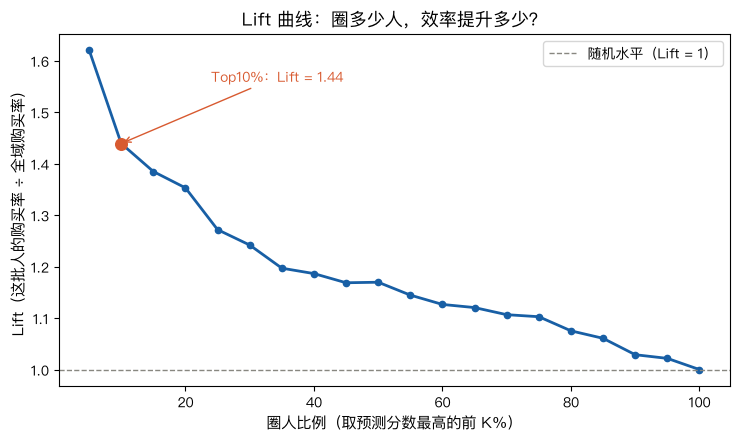

In [21]:
# 计算不同圈人比例下的 Lift
ks = np.arange(0.05, 1.0001, 0.05)
order = np.argsort(-y_prob)
yt = np.asarray(y_test)
lifts = [yt[order[:max(1, int(len(yt) * k))]].mean() / yt.mean() for k in ks]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(ks * 100, lifts, marker='o', color='#185FA5', linewidth=2, markersize=4.5)
ax.axhline(1.0, color='#888780', linewidth=1, linestyle='--',
           label='随机水平（Lift = 1）')

# 标注 Top10% 这个点
ax.scatter([10], [lifts[1]], color='#D85A30', s=70, zorder=5)
ax.annotate(f'Top10%：Lift = {lifts[1]:.2f}',
            xy=(10, lifts[1]), xytext=(24, lifts[1] + 0.12),
            fontsize=10, color='#D85A30',
            arrowprops=dict(arrowstyle='->', color='#D85A30', lw=1))

ax.set_xlabel('圈人比例（取预测分数最高的前 K%）', fontsize=11)
ax.set_ylabel('Lift（这批人的购买率 ÷ 全域购买率）', fontsize=11)
ax.set_title('Lift 曲线：圈多少人，效率提升多少？', fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

**解读**

- **AUC 0.5862：过线了，但增量有限。**&#8203; 模型确实比"直接看一个特征"（0.579）好，但只高 0.007。这符合 1.5 的诊断预期——本数据真正有效的信号只有一个特征，模型能做的增量本来就有限。测试集（0.5862）略低于 CV 验证集（0.6015），属正常波动。
- **Lift@Top10% = 1.44：这是模型在业务上可量化的价值。**&#8203; 给预测分数最高的前 194 人（10%）发券，这批人的购买率是 44.8%；如果随机发 194 张，只有 31.2%。**同样 194 张券，用模型挑人比随机挑，命中率高出 13.6 个百分点；换算成倍数，是随机发的 1.44 倍**（44.8% ÷ 31.2% = 1.44，即 Lift）。
&#8203;
- **Precision 44.8% 好不好，不能孤立地看**——它的基准是随机圈人的 31.2%。44.8% 比 31.2% 高 **13.6 个百分点**（相对提升 44%，即 Lift = 1.44），这就是模型的增量。至于这个增量值不值得投入，取决于券的成本和带来的收益（本数据没有金额字段，无法计算 ROI）。
- **Recall 只有 14.3%，不是模型的问题**——因为我们只圈了 10% 的人，注定只能覆盖一部分买家。捞回的买家比例 ≈ 圈人比例 × Lift，想提高 recall 就得多圈人，代价是 precision 下降。
- **圈多少人（K %）由预算来权衡决定，不是由哪个数字好看决定，所以没有最优解。**&#8203; 券少、要精准（高门槛定向券）就取 top 5%；券多、要覆盖（全站满减）就取 top 50%。实际取多少，取决于预算能发多少张券。
- **为什么不用默认阈值 0.5：**&#8203; 如果按模型的 `predict()`（内部用 0.5 切），只会判出 36 人"会买"，捞回 3.1% 的买家。原因是全域购买率只有 31.2%，模型输出的概率普遍低于 0.5。 **所以本场景不用固定阈值，而是按预算取 TopK**——模型输出的不是一个"买 / 不买"的判断，而是一个**排序**，排序才是它的用途。

### 1.10 特征重要性

- 我们想要查出，9个特征里，哪些真正在起作用？ 这里我们用逻辑回归的**标准化系数** （`coef_`） 来衡量。
- 1.8 里逻辑回归套了 Pipeline 做标准化，所以每个特征的系数都是"同一个尺度"下的——**可以直接横向比较大小**。

In [22]:
# LR 的标准化系数
coef = best_model.named_steps['clf'].coef_[0]     # 从 Pipeline 里取出 LR 的系数

importance = (pd.DataFrame({'特征': FEATURES, '系数': coef})
                .assign(绝对值=lambda d: d['系数'].abs())
                .sort_values('绝对值', ascending=False)
                .reset_index(drop=True))
importance.insert(0, '排名', range(1, len(importance) + 1))

print("=" * 66)
print("LR 标准化系数（按 |系数| 降序，绝对值越大 = 影响越强）")
print("=" * 66)
print(importance.round(4).to_string(index=False))
print("-" * 66)
print(f"最强特征：{importance.loc[0, '特征']}（系数 {importance.loc[0, '系数']:+.4f}）")
print(f"最弱特征：{importance.iloc[-1]['特征']}（系数 {importance.iloc[-1]['系数']:+.4f}）")
print(f"最强 / 最弱 = {importance['绝对值'].max() / importance['绝对值'].min():.1f} 倍")


LR 标准化系数（按 |系数| 降序，绝对值越大 = 影响越强）
 排名                     特征      系数    绝对值
  1            obs_buy_cnt  0.2772 0.2772
  2       obs_recency_days -0.1790 0.1790
  3                 pv_cnt -0.1012 0.1012
  4               cart_cnt  0.0803 0.0803
  5            active_days -0.0759 0.0759
  6                 n_cats -0.0223 0.0223
  7 days_since_last_active -0.0131 0.0131
  8             cart_depth  0.0085 0.0085
  9                fav_cnt  0.0061 0.0061
------------------------------------------------------------------
最强特征：obs_buy_cnt（系数 +0.2772）
最弱特征：fav_cnt（系数 +0.0061）
最强 / 最弱 = 45.6 倍


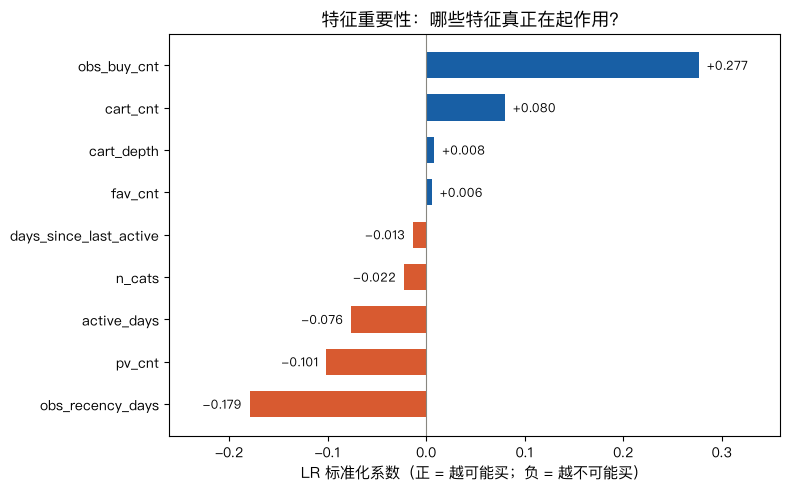

In [23]:
# 按系数从小到大排（负的在下、正的在上，读起来直观）
plot_df = importance.sort_values('系数').reset_index(drop=True)
colors = ['#D85A30' if v < 0 else '#185FA5' for v in plot_df['系数']]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_df['特征'], plot_df['系数'], color=colors, height=0.62)
ax.axvline(0, color='#888780', linewidth=0.8)

ax.set_xlabel('LR 标准化系数（正 = 越可能买；负 = 越不可能买）', fontsize=11)
ax.set_title('特征重要性：哪些特征真正在起作用？', fontsize=13)

# 在每根柱子旁标注数值
for i, (feat, v) in enumerate(zip(plot_df['特征'], plot_df['系数'])):
    ax.text(v + (0.008 if v >= 0 else -0.008), i, f'{v:+.3f}',
            va='center', ha='left' if v >= 0 else 'right', fontsize=9)

ax.margins(x=0.18)
plt.tight_layout()
plt.show()


**特征重要性解读：**

-  9 个特征里，只有 2 个真正起作用——`obs_buy_cnt`（观察窗内购买次数）和 `obs_recency_days`（观察窗内最后购买距 12/01 天数）。
- **`obs_buy_cnt`系数最大（+0.2772），且方向为正。** 这说明在观察窗里买得越多的人，大促期间越可能再买。这跟 1.5 的分组购买率（24.2% → 45.7%）完全一致。
- **`obs_recency_days`排第二（−0.1790），方向为负。** 这说明用户距上次购买的天数越大（越久没买），越不可能在大促买东西，这也是比较符合直觉的。
- **其余 7 个特征贡献很有限。** 最强的 `pv_cnt`（−0.1012）也只有第 2 名的 57%，后面几个更是衰减到 0.01 以下。`fav_cnt`（收藏次数）的系数最小（+0.0061），几乎不起作用——这跟我们在前一个 notebook (03_analysis_visualization) 做过的"收藏的 Lift = 0.90（负向）"是同一件事的两个侧面。
- **和第 1.5 章节形成闭环。** 1.5 用两种工具诊断出"只有 `obs_buy_cnt` 有明显区分力"；我们现在用特征重要性验证了同样的结论：`obs_buy_cnt`是最起作用的特征。


### 1.11 结论与业务边界

**一、任务回顾**

用大促开始前 7 天（11/25–12/01）的行为特征，预测用户在大促 2 天（12/02–12/03）内是否会购买。三个模型（逻辑回归、随机森林、XGBoost）对比后，**逻辑回归的模型性能最优**——而且是唯一没有过拟合的模型。

**二、结论**

**1）逻辑回归模型有效，但增量有限。** 用逻辑回归训练模型后，测试集 AUC = **0.5862**，超过及格线 0.579（"直接看最强单特征"的水平），但只高出 0.007。这不是模型的问题——1.5 的诊断已经说明，本数据真正有效的信号只有一个特征，模型能做的增量本来就有限。

**2）真正起作用的是「用户购买历史」。**
特征重要性显示，`obs_buy_cnt`（观察窗内买过几次）和 `obs_recency_days`（最近一次购买距今多久）的系数是其余 7 个特征的 3~45 倍。**这印证了notebook： 03_analysis_visualization 第七章的结论**——真正区分用户的是「新客 vs 老客」，而不是「加不加购」等其他行为。

**3）模型的价值在「排序」，不在「分类」。**
用默认阈值 0.5 判断"买 / 不买"，只能捞回 3.1% 的真买家；改成按预算取 Top10%，捞回 14.3% 的真买家，**命中率是「随机发券」的 1.44 倍**（44.8% vs 随机发券的 31.2%）。**模型输出的是倾向分，不是最终决策。**

**三、业务边界**

**边界 1：这是「倾向预测」，不是「增量预测」。**&#8203;

模型回答的是"谁本来就倾向于在大促买"，**不回答"给谁发券能带来额外增长"**&#8203;。

高倾向用户往往不发券也会买——给他们发券，是营销预算的浪费。要找出"被干预才会买"的人需要 uplift 模型，而那必须有随机实验数据（本数据集没有）。

**边界 2：结论有效期——只适用于大促预热期。**&#8203;

观察窗是常规期（11/25–12/01），预测窗是大促期（12/02–12/03），两者的用户行为模式不同：大促期日均购买用户是观察窗的 **1.86 倍**（1,518 vs 817）。

这种分布偏移不影响排序能力（AUC），但会让模型输出的绝对概率偏高。所以：

> **结论有效期：仅适用大促预热期。外推到常规期，需重新验证。**&#8203;

**边界 3：要验证「发券有没有用」，必须做 A/B 实验。**&#8203;

模型能告诉你"谁更可能买"，但**不能证明"发券让他买了"**&#8203;。验证干预效果的唯一办法是随机分组：实验组发券、对照组不发，比较两组的购买率差异——**这个差异才是净增量**。

这份 9 天观测快照没有随机分流，所以做不到。

**四、模型的实际用法**

| | 说明 |
| :--- | :--- |
| **用途** | 大促前给全量用户打分排序，按预算圈出前 K% 做定向触达 |
| **怎么定 K** | 由预算决定：券少取 5%（命中率 50.5%），券多取 50%（覆盖 58.5% 的买家） |
| **不要用它做** | ① 预测"发券能带来多少增量" ② 外推到常规期 ③ 把绝对概率当作真实购买率 |
